In [2]:

import os

# Proje klasörleri
base = "/content/steam-game-success-prediction"

folders = [
    "notebooks",
    "data",
    "outputs",
    "docs"
]

for folder in folders:
    os.makedirs(os.path.join(base, folder), exist_ok=True)

# Veri kaynağı ve lisans bilgisi
data_info = """# Veri Seti Bilgisi

Adı: Steam Games Dataset 2025
Kaynak: Kaggle - Artemiy Ermilov ve katkıda bulunanlar
Bağlantı: https://www.kaggle.com/datasets/artermiloff/steam-games-dataset
Lisans: MIT

Ham veri dosyası bu GitHub deposuna eklenmeyecektir.
Veri, analiz amacıyla Google Colab ortamında kullanılacaktır.
"""

with open(os.path.join(base, "data", "README.md"), "w") as f:
    f.write(data_info)

# Oluşturulan klasörleri göster
for root, dirs, files in os.walk(base):
    level = root.replace(base, "").count(os.sep)
    print("  " * level + os.path.basename(root) + "/")
    for file in files:
        print("  " * (level + 1) + file)



steam-game-success-prediction/
  notebooks/
  data/
    README.md
  outputs/
  docs/


## A. Veri Tanıtımı

- **Veri setinin adı:** Steam Games Dataset 2025
- **Veri kaynağı:** Kaggle
- **Bağlantı:** https://www.kaggle.com/datasets/artermiloff/steam-games-dataset
- **Lisans:** Kaggle veri seti sayfasından doğrulanacak.
- **Dosya formatı:** CSV (dosyalar incelendikten sonra kesinleştirilecek).
- **Gözlem birimi:** Steam platformunda yer alan oyunlar.
- **Araştırma türü:** Açık kaynak ikincil veri analizi.
- **Araştırmanın amacı:** Oyun özellikleri ve kullanıcı değerlendirmeleri üzerinden oyun başarısını tahmin edebilecek değişkenleri incelemek.


In [3]:

from pathlib import Path
import pandas as pd

# Hocanın verdiği temsili örnek veri
ornek = pd.DataFrame({
    "gun": ["Pzt", "Sal", "Çar", "Per", "Cum"],
    "calisma_saati": [2, 3, 1, 4, 2],
    "tamamlanan_gorev": [1, 2, 1, 3, 2]
})

ornek.to_csv("ornek_ogrenci.csv", index=False)

veri_yolu = "ornek_ogrenci.csv"
veri = pd.read_csv(veri_yolu)

print("Temsili veri örneği:")
print(veri.head())



Temsili veri örneği:
   gun  calisma_saati  tamamlanan_gorev
0  Pzt              2                 1
1  Sal              3                 2
2  Çar              1                 1
3  Per              4                 3
4  Cum              2                 2


In [6]:

from google.colab import files
from pathlib import Path
import zipfile

# Kaggle'dan indirdiğin ZIP dosyasını seç
uploaded_files = files.upload()

# Proje veri klasörü
data_dir = Path("/content/steam-game-success-prediction/data/raw")
data_dir.mkdir(parents=True, exist_ok=True)

# ZIP dosyasını aç
for filename, content in uploaded_files.items():
    temp_file = Path("/content") / filename
    temp_file.write_bytes(content)

    if filename.lower().endswith(".zip"):
        with zipfile.ZipFile(temp_file, "r") as archive:
            archive.extractall(data_dir)

    elif filename.lower().endswith(".csv"):
        (data_dir / filename).write_bytes(content)

# CSV dosyalarını bul
csv_files = list(data_dir.rglob("*.csv"))

print("Bulunan CSV dosyaları:")
for file in csv_files:
    print(file.name, "-", round(file.stat().st_size / (1024 * 1024), 2), "MB")

print("\nToplam CSV dosyası:", len(csv_files))



Saving games_march2025_cleaned.csv to games_march2025_cleaned.csv
Saving games_march2025_full.csv to games_march2025_full.csv
Saving games_may2024_cleaned.csv to games_may2024_cleaned.csv
Saving games_may2024_full.csv to games_may2024_full.csv
Bulunan CSV dosyaları:
games_may2024_full.csv - 405.23 MB
games_march2025_cleaned.csv - 446.93 MB
games_march2025_full.csv - 449.65 MB
games_may2024_cleaned.csv - 402.75 MB

Toplam CSV dosyası: 4


In [7]:

import os

dosya = "/content/games_march2025_cleaned.csv"

if os.path.exists(dosya):
    print("Dosya bulundu!")
    print("Boyut:", round(os.path.getsize(dosya) / (1024**2), 2), "MB")
else:
    print("Dosya bulunamadı.")



Dosya bulundu!
Boyut: 446.93 MB


In [8]:

import pandas as pd

dosya = "/content/games_march2025_cleaned.csv"

veri = pd.read_csv(dosya, nrows=5)

print("Sütun isimleri:")
print(veri.columns.tolist())

print("\nİlk 5 kayıt:")
display(veri)


Sütun isimleri:
['appid', 'name', 'release_date', 'required_age', 'price', 'dlc_count', 'detailed_description', 'about_the_game', 'short_description', 'reviews', 'header_image', 'website', 'support_url', 'support_email', 'windows', 'mac', 'linux', 'metacritic_score', 'metacritic_url', 'achievements', 'recommendations', 'notes', 'supported_languages', 'full_audio_languages', 'packages', 'developers', 'publishers', 'categories', 'genres', 'screenshots', 'movies', 'user_score', 'score_rank', 'positive', 'negative', 'estimated_owners', 'average_playtime_forever', 'average_playtime_2weeks', 'median_playtime_forever', 'median_playtime_2weeks', 'discount', 'peak_ccu', 'tags', 'pct_pos_total', 'num_reviews_total', 'pct_pos_recent', 'num_reviews_recent']

İlk 5 kayıt:


,appid,name,release_date,required_age,price,dlc_count,detailed_description,about_the_game,short_description,reviews,...,average_playtime_2weeks,median_playtime_forever,median_playtime_2weeks,discount,peak_ccu,tags,pct_pos_total,num_reviews_total,pct_pos_recent,num_reviews_recent
0,730,Counter-Strike 2,2012-08-21,0,0.00,1,"For over two decades, Counter-Strike has offer...","For over two decades, Counter-Strike has offer...","For over two decades, Counter-Strike has offer...",NaN,...,879,5174,350,0,1212356,"{'FPS': 90857, 'Shooter': 65397, 'Multiplayer'...",86,8632939,82,96473
1,578080,PUBG: BATTLEGROUNDS,2017-12-21,0,0.00,0,"LAND, LOOT, SURVIVE! Play PUBG: BATTLEGROUNDS ...","LAND, LOOT, SURVIVE! Play PUBG: BATTLEGROUNDS ...",Play PUBG: BATTLEGROUNDS for free. Land on str...,NaN,...,0,0,0,0,616738,"{'Survival': 14838, 'Shooter': 12727, 'Battle ...",59,2513842,68,16720
2,570,Dota 2,2013-07-09,0,0.00,2,"The most-played game on Steam. Every day, mill...","The most-played game on Steam. Every day, mill...","Every day, millions of players worldwide enter...",“A modern multiplayer masterpiece.” 9.5/10 – D...,...,1536,898,892,0,555977,"{'Free to Play': 59933, 'MOBA': 20158, 'Multip...",81,2452595,80,29366
3,271590,Grand Theft Auto V Legacy,2015-04-13,17,0.00,0,"When a young street hustler, a retired bank ro...","When a young street hustler, a retired bank ro...",Grand Theft Auto V for PC offers players the o...,NaN,...,771,7101,74,0,117698,"{'Open World': 32644, 'Action': 23539, 'Multip...",87,1803832,92,17517
4,359550,Tom Clancy's Rainbow Six® Siege,2015-12-01,17,3.99,9,Edition Comparison Ultimate Edition The Tom Cl...,“One of the best first-person shooters ever ma...,"Tom Clancy's Rainbow Six® Siege is an elite, t...",NaN,...,682,2434,306,80,89916,"{'FPS': 9831, 'PvP': 9162, 'e-sports': 9072, '...",84,1168020,76,12608


## C. Veri İnceleme ve Hesaplama

Bu aşamada Steam Games Dataset 2025 veri setinin
genel yapısı, gözlem sayısı, değişkenleri ve eksik
verileri incelenmektedir.


In [9]:

import pandas as pd
from pathlib import Path

dosya = "/content/games_march2025_cleaned.csv"

# Sütun isimlerini al
sutunlar = pd.read_csv(dosya, nrows=0).columns

# Eksik değer ve satır sayılarını parça parça hesapla
eksik_sayilari = pd.Series(0, index=sutunlar, dtype="int64")
toplam_satir = 0

for parca in pd.read_csv(dosya, chunksize=100000):
    toplam_satir += len(parca)
    eksik_sayilari += parca.isna().sum()

print("Toplam oyun sayısı:", toplam_satir)
print("Toplam sütun sayısı:", len(sutunlar))

# Eksik veri tablosu
eksik_tablo = pd.DataFrame({
    "Sütun": sutunlar,
    "Eksik Değer": eksik_sayilari.values,
    "Eksik Yüzdesi (%)": (
        eksik_sayilari.values / toplam_satir * 100
    ).round(2)
})

eksik_tablo = eksik_tablo.sort_values(
    "Eksik Değer", ascending=False
)

display(eksik_tablo.head(15))

# Sonuçları kaydet
cikti = Path("/content/steam-game-success-prediction/outputs")
cikti.mkdir(parents=True, exist_ok=True)

eksik_tablo.to_csv(
    cikti / "ozet.csv",
    index=False
)

print("Özet dosyası kaydedildi!")



Toplam oyun sayısı: 89618
Toplam sütun sayısı: 47


,Sütun,Eksik Değer,Eksik Yüzdesi (%)
32,score_rank,89579,99.96
18,metacritic_url,86071,96.04
9,reviews,79217,88.39
21,notes,72975,81.43
11,website,48504,54.12
12,support_url,45508,50.78
13,support_email,10820,12.07
7,about_the_game,220,0.25
6,detailed_description,197,0.22
8,short_description,120,0.13


Özet dosyası kaydedildi!


## D. Grafik ve Temel İstatistikler

Bu aşamada oyunların fiyatları, toplam kullanıcı değerlendirme
sayıları ve pozitif değerlendirme oranları incelenmiştir.
Pozitif değerlendirme oranının dağılımı histogram grafiği
kullanılarak görselleştirilmiştir.


TEMEL İSTATİSTİKLER


,price,pct_pos_total,num_reviews_total
count,89618.00,89618.00,89618.00
mean,7.31,45.35,1315.49
std,13.33,40.69,35423.70
min,0.00,-1.00,-1.00
25%,0.99,-1.00,-1.00
50%,4.99,60.00,15.00
75%,9.99,84.00,81.00
max,999.98,100.00,8632939.00



Pozitif değerlendirme oranı aralığı:
-1 - 100


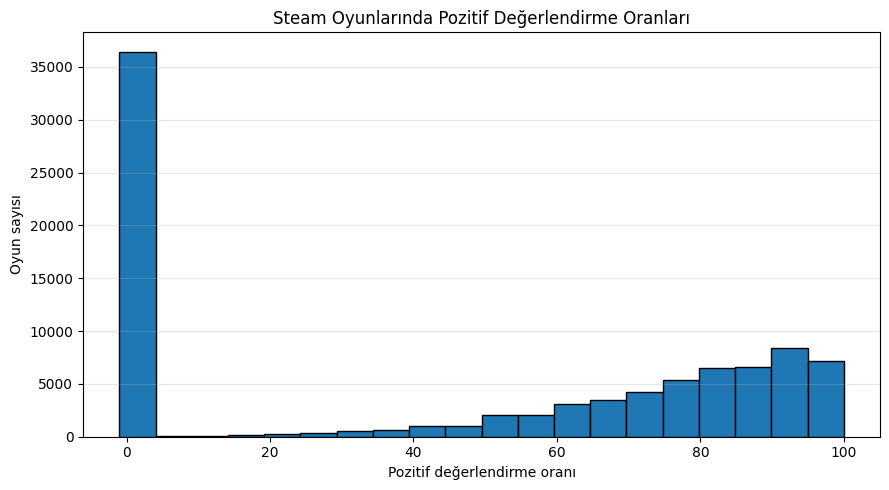

Grafik ve özet dosyaları kaydedildi.


In [10]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

dosya = "/content/games_march2025_cleaned.csv"

# Yalnızca gerekli üç sütunu oku
analiz = pd.read_csv(
    dosya,
    usecols=["price", "pct_pos_total", "num_reviews_total"]
)

# Sayısal değerlere dönüştür
for sutun in ["price", "pct_pos_total", "num_reviews_total"]:
    analiz[sutun] = pd.to_numeric(
        analiz[sutun], errors="coerce"
    )

# Temel istatistikler
print("TEMEL İSTATİSTİKLER")
display(analiz.describe().round(2))

print("\nPozitif değerlendirme oranı aralığı:")
print(analiz["pct_pos_total"].min(),
      "-", analiz["pct_pos_total"].max())

# Sonuç klasörü
cikti = Path("/content/steam-game-success-prediction/outputs")
cikti.mkdir(parents=True, exist_ok=True)

# İstatistikleri kaydet
analiz.describe().round(2).to_csv(cikti / "ozet.csv")

# Pozitif değerlendirme oranı grafiği
grafik_verisi = analiz["pct_pos_total"].dropna()

plt.figure(figsize=(9, 5))
plt.hist(grafik_verisi, bins=20, edgecolor="black")
plt.title("Steam Oyunlarında Pozitif Değerlendirme Oranları")
plt.xlabel("Pozitif değerlendirme oranı")
plt.ylabel("Oyun sayısı")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(cikti / "grafik.png", dpi=160)
plt.show()

print("Grafik ve özet dosyaları kaydedildi.")


GEÇERSİZ KOD KONTROLÜ
price : 0
pct_pos_total : 36419
num_reviews_total : 36419

DÜZELTİLMİŞ TEMEL İSTATİSTİKLER


,price,pct_pos_total,num_reviews_total
count,89618.00,53199.00,53199.00
mean,7.31,77.08,2216.73
std,13.33,17.63,45955.34
min,0.00,0.00,10.00
25%,0.99,67.00,21.00
50%,4.99,81.00,55.00
75%,9.99,91.00,238.00
max,999.98,100.00,8632939.00


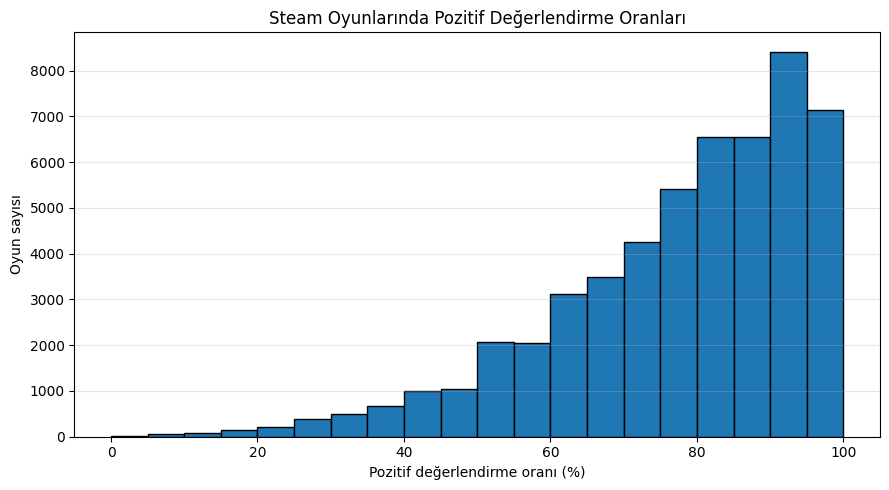

Düzeltilmiş analiz ve grafik kaydedildi.


In [11]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Önceki analizde oluşturduğumuz veri
analiz_temiz = analiz.copy()

# -1 değerlerinin kaç tane olduğunu kontrol et
print("GEÇERSİZ KOD KONTROLÜ")

for sutun in ["price", "pct_pos_total", "num_reviews_total"]:
    print(sutun, ":", (analiz_temiz[sutun] == -1).sum())

# -1 değerlerini eksik değer olarak değerlendir
analiz_temiz = analiz_temiz.replace(-1, float("nan"))

# Pozitif değerlendirme oranı yalnızca 0-100 aralığında olmalı
analiz_temiz.loc[
    ~analiz_temiz["pct_pos_total"].between(0, 100),
    "pct_pos_total"
] = float("nan")

print("\nDÜZELTİLMİŞ TEMEL İSTATİSTİKLER")
display(analiz_temiz.describe().round(2))

# Çıktı klasörü
cikti = Path("/content/steam-game-success-prediction/outputs")
cikti.mkdir(parents=True, exist_ok=True)

# İstatistikleri kaydet
analiz_temiz.describe().round(2).to_csv(
    cikti / "ozet.csv"
)

# Düzeltilmiş grafik
grafik_verisi = analiz_temiz["pct_pos_total"].dropna()

plt.figure(figsize=(9, 5))
plt.hist(grafik_verisi, bins=20, edgecolor="black")
plt.title("Steam Oyunlarında Pozitif Değerlendirme Oranları")
plt.xlabel("Pozitif değerlendirme oranı (%)")
plt.ylabel("Oyun sayısı")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(cikti / "grafik.png", dpi=160)
plt.show()

print("Düzeltilmiş analiz ve grafik kaydedildi.")



## E. Akademik Yorum

Araştırmada kullanılan veri setinde toplam 89.618 oyun kaydı ve 47 değişken bulunmaktadır. İncelenen değişkenler arasında oyun fiyatının ortalaması 7,31, ortancası ise 4,99 olarak hesaplanmıştır. Pozitif kullanıcı değerlendirme oranının geçerli 53.199 kayıttaki ortalaması %77,08, ortancası ise %81'dir. Toplam kullanıcı değerlendirme sayısının ortalaması 2.216,73 iken ortancası 55 olarak bulunmuştur; bu fark, bazı oyunların çok yüksek sayıda kullanıcı değerlendirmesine sahip olduğunu göstermektedir. Pozitif değerlendirme oranlarının grafiğinde oyunların önemli bir bölümünün yüksek değerlendirme oranlarında toplandığı görülmektedir.

**Veri sınırlılıkları:** Pozitif değerlendirme oranı ve toplam değerlendirme sayısı değişkenlerinde -1 değeri bulunan 36.419 kayıt, bu analiz kapsamında geçersiz değer olarak değerlendirilerek ilgili hesaplamaların dışında bırakılmıştır. Ayrıca bazı değişkenlerde yüksek oranda eksik veri bulunmaktadır. Bu nedenle elde edilen sonuçlar veri setindeki mevcut kayıtlarla sınırlıdır ve tek başına neden-sonuç ilişkisi göstermemektedir.


In [13]:

from pathlib import Path

cikti = Path("/content/steam-game-success-prediction/outputs")
cikti.mkdir(parents=True, exist_ok=True)

# Eksik veri tablosu
eksik_tablo.to_csv(
    cikti / "eksik_veri_ozeti.csv",
    index=False
)

# Temel istatistikler
analiz_temiz.describe().round(2).to_csv(
    cikti / "ozet.csv"
)

print("Oluşturulan dosyalar:")
for dosya in cikti.iterdir():
    print(dosya.name)


Oluşturulan dosyalar:
ozet.csv
eksik_veri_ozeti.csv
grafik.png


In [14]:

import shutil
from google.colab import files

klasor = "/content/steam-game-success-prediction/outputs"

zip_yolu = shutil.make_archive(
    "/content/steam_analiz_ciktilari",
    "zip",
    klasor
)

files.download(zip_yolu)



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>